# **Machine Learning & Data Analysis — PIM-1/MOC-Ph Mixed Matrix Membranes**
### Supporting analysis for Manuscript 3 (CO₂/N₂ separation performance of PIM-1/MOC-Ph MMMs)



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel as C, WhiteKernel
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 120

print("Libraries loaded.")

Libraries loaded.


# **1. Load data**


In [ ]:
# ============================================================
# STEP 1 — Upload file to google colab
# ============================================================

import pandas as pd
from google.colab import files
import os

# Upload the Excel file
uploaded = files.upload()

# Display uploaded files
print("\nUploaded files:")
for filename in uploaded.keys():
    print(" -", filename)

# Automatically identify the uploaded Excel file
excel_files = [
    f for f in uploaded.keys()
    if f.lower().endswith((".xlsx", ".xls"))
]

if len(excel_files) == 0:
    raise FileNotFoundError(
        "No Excel file was uploaded. Please upload Results-P3.xlsx."
    )

if len(excel_files) > 1:
    print("\nMultiple Excel files detected:")
    for f in excel_files:
        print(" -", f)

# Use Results-P3.xlsx if available
matching_files = [
    f for f in excel_files
    if f.lower() == "results-p3.xlsx"
]

if matching_files:
    filename = matching_files[0]
else:
    filename = excel_files[0]

print("\nUsing file:")
print(filename)

# Verify file exists
print("\nFile path:")
print(os.path.abspath(filename))

# Load workbook
excel = pd.ExcelFile(filename)

print("\nAvailable sheets:")
for sheet in excel.sheet_names:
    print(" -", sheet)

Saving Results-P3.xlsx to Results-P3.xlsx

Uploaded files:
 - Results-P3.xlsx

Using file:
Results-P3.xlsx

File path:
/content/Results-P3.xlsx

Available sheets:
 - Fig 2(C)
 - Fig 2(D)
 - Fig 2(E)
 - Fig 2(F)
 - Fig 3(B)
 - Fig 3(C)
 - Fig 3(D)
 - Fig 5(A)
 - Fig 5(B)
 - Fig 6(A)
 - Fig 6(B)
 - Fig 7(A)
 - Fig 7(B)
 - Fig 7(C)
 - Fig 8(A)
 - Fig 8(B)
 - Fig 8(C)
 - Fig 9(A)
 - Fig 9(B)
 - Fig 9(C)
 - F. Aging Study
 - Hypothetical (Not Data)


# **2. Predictive modeling — pressure & loading effects**


In [ ]:
df_perm = pd.read_excel(filename, sheet_name="Fig 8(A)")
df_sel  = pd.read_excel(filename, sheet_name="Fig 8(B)")

pressure_col_perm = df_perm.columns[0]
pressure_col_sel  = df_sel.columns[0]

perm_long = df_perm.melt(id_vars=[pressure_col_perm], var_name="Membrane",
                          value_name="CO2_Permeability_Barrer").rename(
                          columns={pressure_col_perm: "Pressure_bar"})

sel_long = df_sel.melt(id_vars=[pressure_col_sel], var_name="Membrane",
                        value_name="CO2_N2_Selectivity").rename(
                        columns={pressure_col_sel: "Pressure_bar"})

ml_data = pd.merge(perm_long, sel_long, on=["Pressure_bar", "Membrane"], how="inner").dropna()

loading_map = {"PIM-1": 0.0, "PIM-Ph-0.5%": 0.5, "PIM-Ph-1%": 1.0,
               "PIM-Ph-5%": 5.0, "PIM-Ph-10%": 10.0}

ml_data["MOC_Ph_loading_wt%"] = ml_data["Membrane"].map(loading_map)
ml_data["Temperature_C"] = 35.0
ml_data = ml_data.dropna(subset=["MOC_Ph_loading_wt%"]).reset_index(drop=True)

ml_data = ml_data[["Membrane", "MOC_Ph_loading_wt%", "Pressure_bar",
                    "Temperature_C", "CO2_Permeability_Barrer", "CO2_N2_Selectivity"]]

print("Dataset shape:", ml_data.shape)
print("\nMissing values:", ml_data.isnull().sum().sum(), "| Duplicate rows:", ml_data.duplicated().sum())
display(ml_data.describe())
ml_data.head()

Dataset shape: (35, 6)

Missing values: 0 | Duplicate rows: 0


,MOC_Ph_loading_wt%,Pressure_bar,Temperature_C,CO2_Permeability_Barrer,CO2_N2_Selectivity
count,35.000000,35.000000,35.0,35.000000,35.000000
mean,3.300000,15.142857,35.0,8631.428571,42.914286
std,3.844783,9.932546,0.0,2892.665312,17.033482
min,0.000000,1.000000,35.0,3200.000000,12.000000
25%,0.500000,5.000000,35.0,6700.000000,30.000000
50%,1.000000,15.000000,35.0,8500.000000,45.000000
75%,5.000000,25.000000,35.0,11700.000000,55.000000
max,10.000000,30.000000,35.0,12500.000000,72.000000


,Membrane,MOC_Ph_loading_wt%,Pressure_bar,Temperature_C,CO2_Permeability_Barrer,CO2_N2_Selectivity
0,PIM-1,0.0,1,35.0,3200,20
1,PIM-1,0.0,5,35.0,3600,21
2,PIM-1,0.0,10,35.0,4300,21
3,PIM-1,0.0,15,35.0,4600,21
4,PIM-1,0.0,20,35.0,4900,21


# **2.2 Exploratory trends**

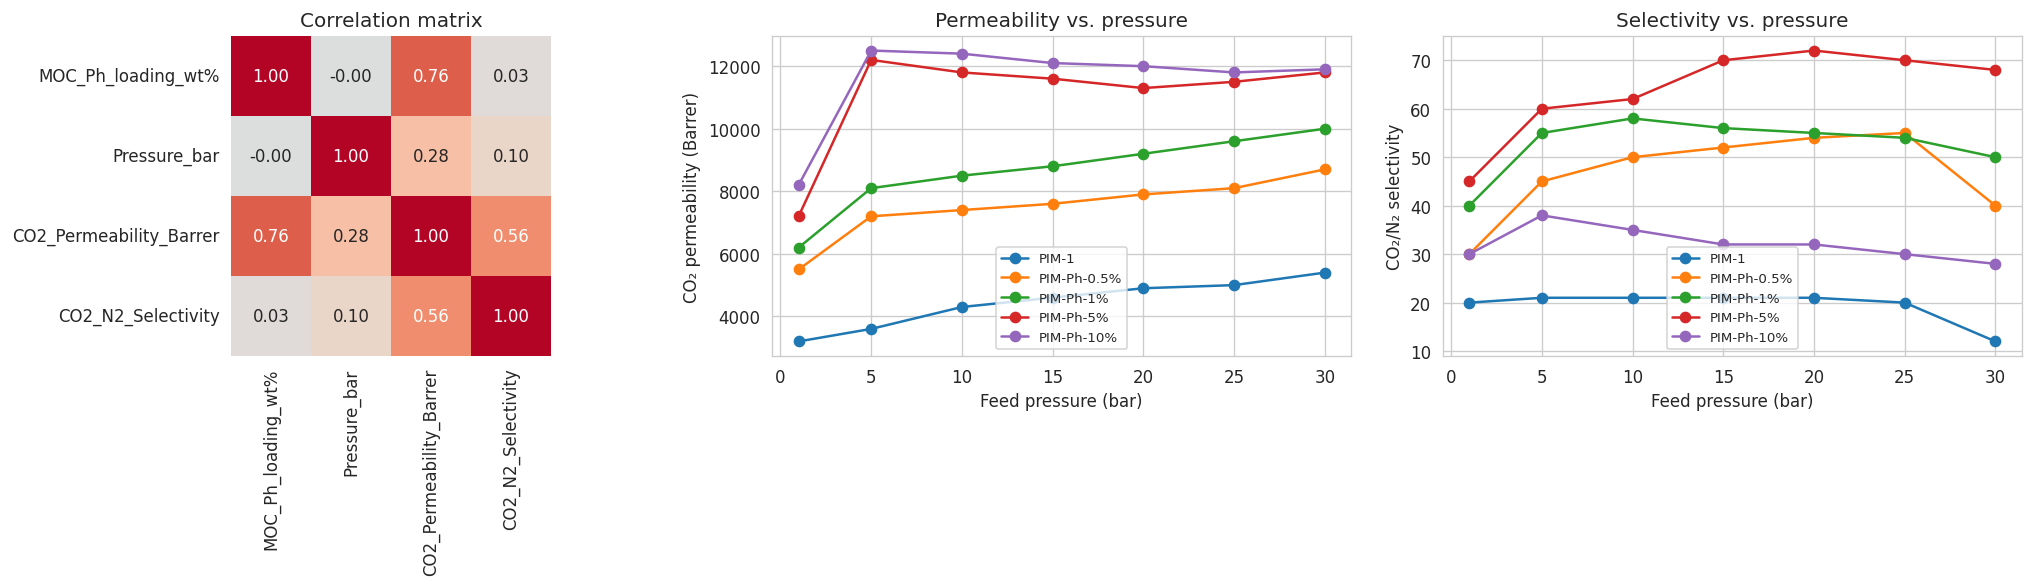

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

corr_cols = ["MOC_Ph_loading_wt%", "Pressure_bar", "CO2_Permeability_Barrer", "CO2_N2_Selectivity"]
sns.heatmap(ml_data[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0,
            square=True, ax=axes[0], cbar=False)
axes[0].set_title("Correlation matrix")

for membrane in ml_data["Membrane"].unique():
    subset = ml_data[ml_data["Membrane"] == membrane]
    axes[1].plot(subset["Pressure_bar"], subset["CO2_Permeability_Barrer"], marker="o", label=membrane)
    axes[2].plot(subset["Pressure_bar"], subset["CO2_N2_Selectivity"], marker="o", label=membrane)

axes[1].set_xlabel("Feed pressure (bar)"); axes[1].set_ylabel("CO₂ permeability (Barrer)")
axes[1].set_title("Permeability vs. pressure"); axes[1].legend(fontsize=8)

axes[2].set_xlabel("Feed pressure (bar)"); axes[2].set_ylabel("CO₂/N₂ selectivity")
axes[2].set_title("Selectivity vs. pressure"); axes[2].legend(fontsize=8)

plt.tight_layout()
plt.savefig("Figure_ML_Exploratory_Overview.png", dpi=600, bbox_inches="tight")
plt.show()

# **2.3 Model comparison (leave-one-membrane-out cross-validation)**

In [ ]:
models = {
    "Linear Regression": Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())]),
    "Ridge Regression": Pipeline([("scaler", StandardScaler()), ("model", Ridge(alpha=1.0))]),
    "Random Forest": RandomForestRegressor(n_estimators=500, max_depth=5, min_samples_leaf=2, random_state=42),
    "SVR (RBF)": Pipeline([("scaler", StandardScaler()), ("model", SVR(kernel="rbf", C=10, epsilon=0.01, gamma="scale"))]),
    "Gaussian Process": Pipeline([("scaler", StandardScaler()), ("model", GaussianProcessRegressor(
        kernel=C(1.0, (1e-3, 1e3)) * RBF(1.0, (1e-3, 1e3)) + WhiteKernel(1e-3),
        normalize_y=True, random_state=42, n_restarts_optimizer=5))]),
}

features = ["MOC_Ph_loading_wt%", "Pressure_bar"]
X = ml_data[features].values
groups = ml_data["Membrane"].values

logo = LeaveOneGroupOut()

def evaluate_models(X, y, groups, models):
    results, predictions = [], {}
    for name, model in models.items():
        y_true_all, y_pred_all = [], []
        for train_idx, test_idx in logo.split(X, y, groups):
            model.fit(X[train_idx], y[train_idx])
            y_pred = model.predict(X[test_idx])
            y_true_all.extend(y[test_idx])
            y_pred_all.extend(y_pred)
        y_true_all, y_pred_all = np.array(y_true_all), np.array(y_pred_all)
        results.append({
            "Model": name,
            "RMSE": np.sqrt(mean_squared_error(y_true_all, y_pred_all)),
            "MAE": mean_absolute_error(y_true_all, y_pred_all),
            "R2": r2_score(y_true_all, y_pred_all),
        })
        predictions[name] = {"Actual": y_true_all, "Predicted": y_pred_all}
    return pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True), predictions

y_perm = ml_data["CO2_Permeability_Barrer"].values
y_sel  = ml_data["CO2_N2_Selectivity"].values

perm_results, perm_predictions = evaluate_models(X, y_perm, groups, models)
sel_results, sel_predictions   = evaluate_models(X, y_sel, groups, models)

print("CO2 permeability — LOGO-CV performance:")
display(perm_results)
print("\nCO2/N2 selectivity — LOGO-CV performance:")
display(sel_results)

CO2 permeability — LOGO-CV performance:


,Model,RMSE,MAE,R2
0,Random Forest,2509.007747,2225.450987,0.225544
1,Gaussian Process,2773.032388,2405.282493,0.053975
2,Ridge Regression,3066.318252,2592.719686,-0.156717
3,Linear Regression,3152.570162,2653.851803,-0.222707
4,SVR (RBF),3365.696196,2929.164202,-0.393614



CO2/N2 selectivity — LOGO-CV performance:


,Model,RMSE,MAE,R2
0,SVR (RBF),18.433829,15.713762,-0.205628
1,Gaussian Process,19.254771,17.015441,-0.315404
2,Random Forest,24.192672,20.956362,-1.076586
3,Ridge Regression,36.241416,29.943134,-3.660072
4,Linear Regression,36.945756,30.372225,-3.842966


# **2.4 Model comparison figure (RMSE / MAE / R²)**

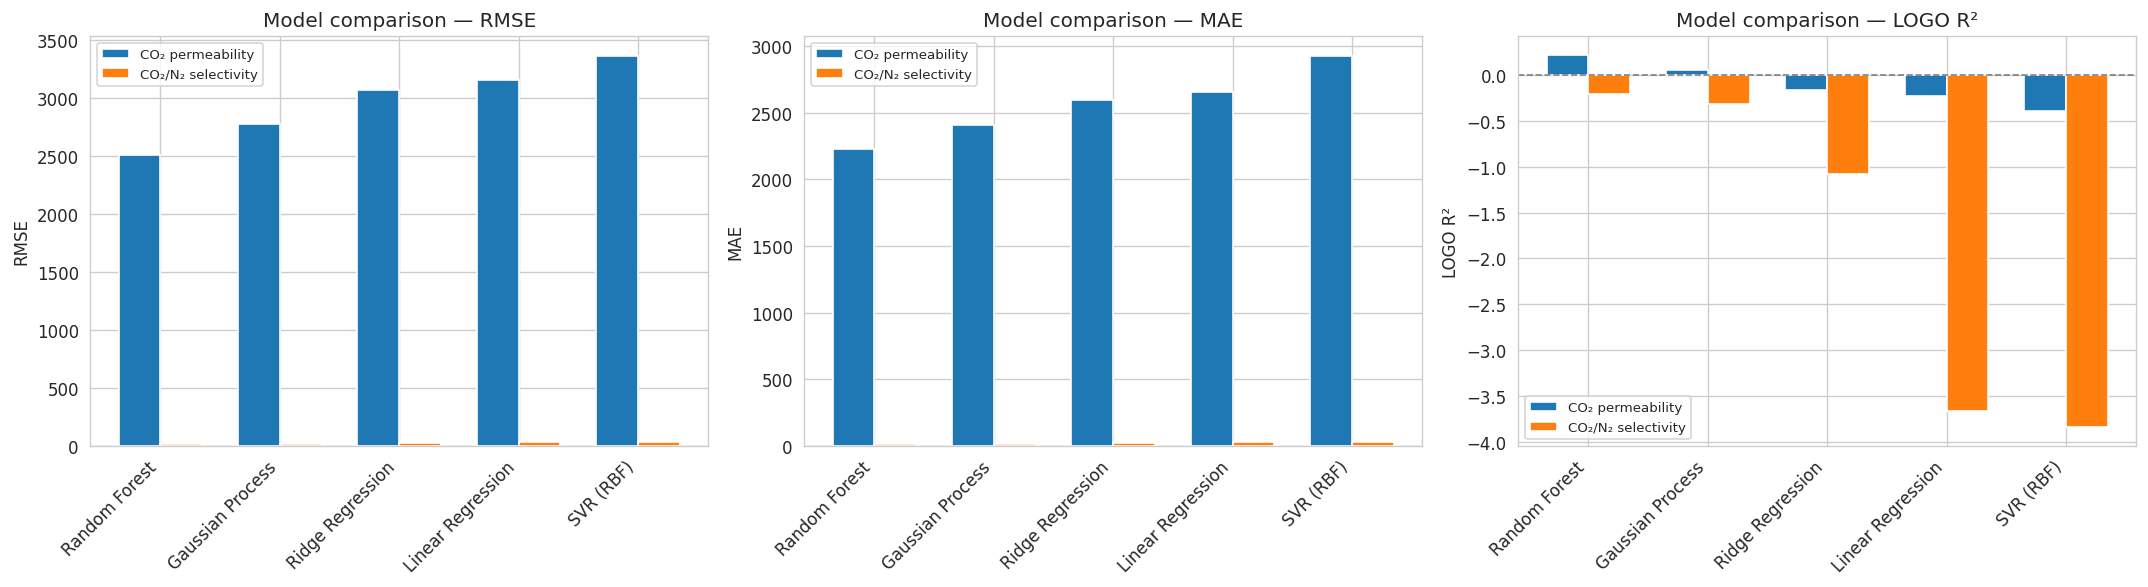

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
x = np.arange(len(perm_results))
width = 0.35

for ax, metric, ylabel in zip(axes, ["RMSE", "MAE", "R2"], ["RMSE", "MAE", "LOGO R²"]):
    ax.bar(x - width/2, perm_results[metric], width, label="CO₂ permeability")
    ax.bar(x + width/2, sel_results[metric], width, label="CO₂/N₂ selectivity")
    ax.set_xticks(x); ax.set_xticklabels(perm_results["Model"], rotation=45, ha="right")
    ax.set_ylabel(ylabel); ax.set_title(f"Model comparison — {ylabel}")
    ax.legend(fontsize=8)
axes[2].axhline(0, linestyle="--", linewidth=1, color="grey")

plt.tight_layout()
plt.savefig("Figure_ML_Model_Comparison.png", dpi=600, bbox_inches="tight")
plt.show()

# **2.5 Actual vs. predicted and residuals (best model per target)**

Best permeability model: Random Forest
Best selectivity model: SVR (RBF)


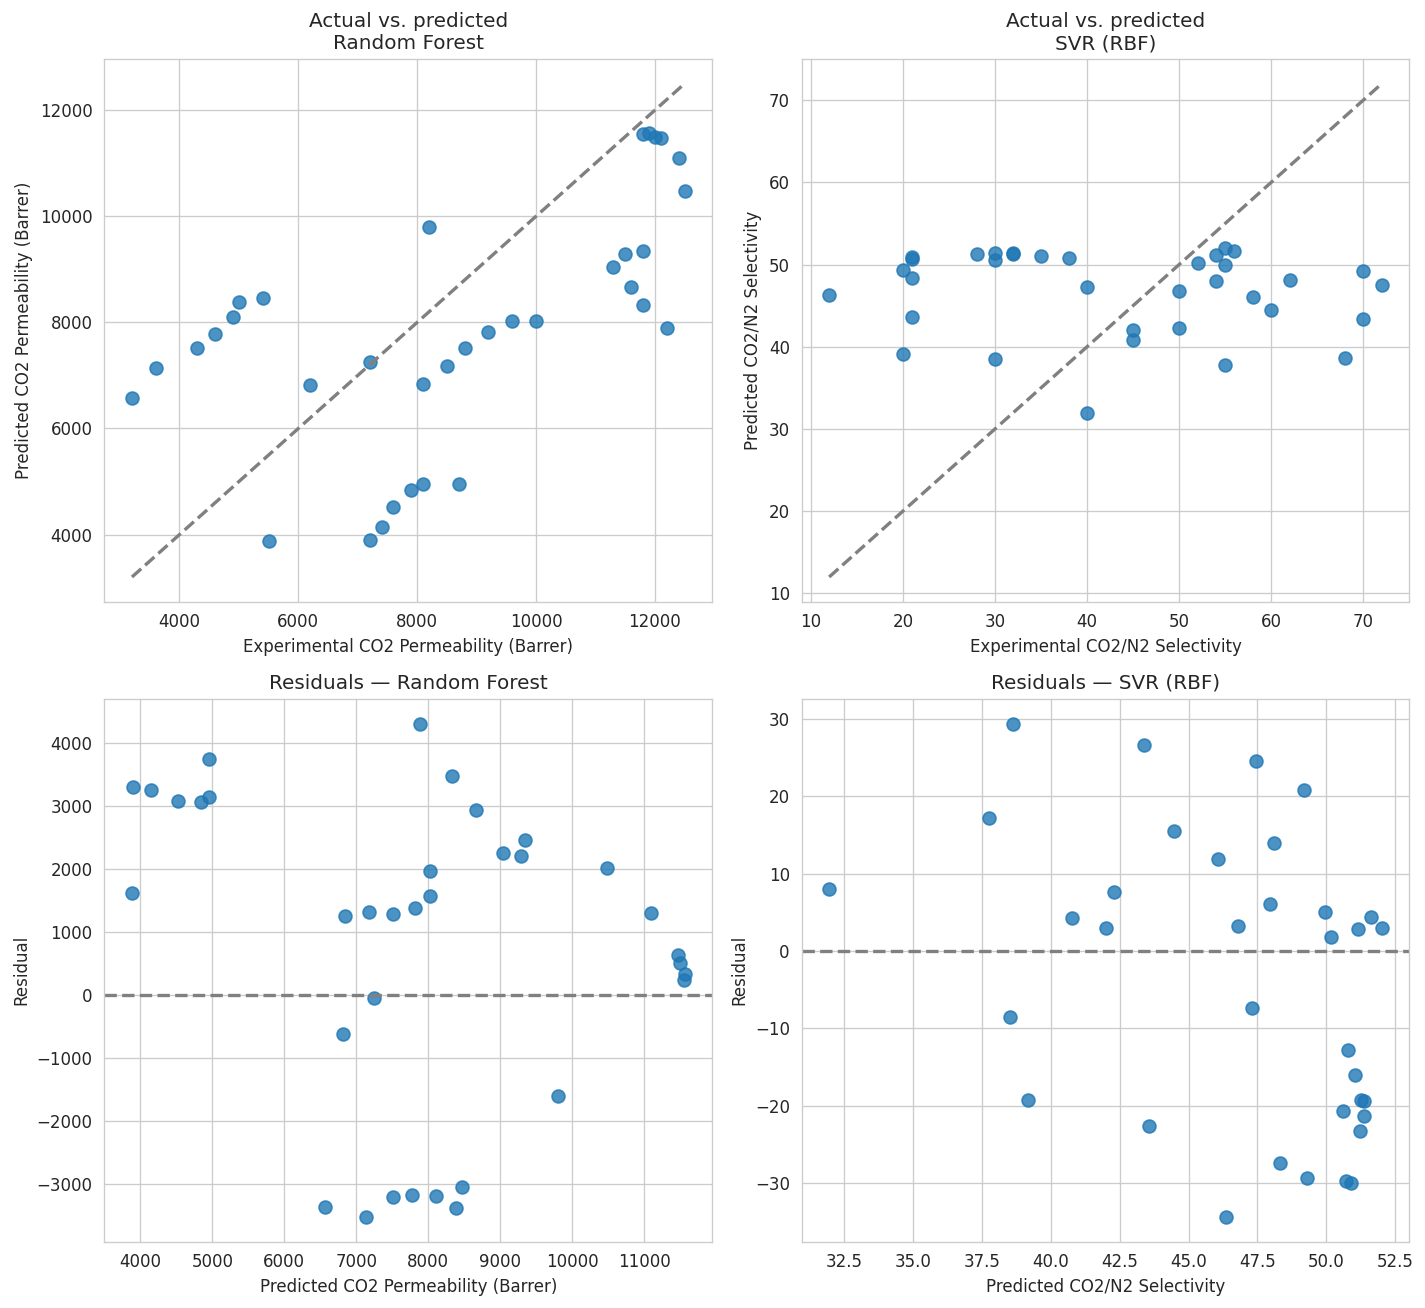

In [ ]:
best_perm_model = perm_results.iloc[0]["Model"]
best_sel_model  = sel_results.iloc[0]["Model"]
print("Best permeability model:", best_perm_model)
print("Best selectivity model:", best_sel_model)

fig, axes = plt.subplots(2, 2, figsize=(12, 11))

for col, (target_name, results_df, predictions) in enumerate([
    ("CO2 Permeability (Barrer)", perm_results, perm_predictions),
    ("CO2/N2 Selectivity", sel_results, sel_predictions),
]):
    best_model = results_df.iloc[0]["Model"]
    pred = predictions[best_model]

    ax = axes[0, col]
    ax.scatter(pred["Actual"], pred["Predicted"], s=60, alpha=0.8)
    lims = [min(pred["Actual"].min(), pred["Predicted"].min()),
            max(pred["Actual"].max(), pred["Predicted"].max())]
    ax.plot(lims, lims, "--", linewidth=2, color="grey")
    ax.set_xlabel(f"Experimental {target_name}"); ax.set_ylabel(f"Predicted {target_name}")
    ax.set_title(f"Actual vs. predicted\n{best_model}")

    residuals = pred["Actual"] - pred["Predicted"]
    ax2 = axes[1, col]
    ax2.scatter(pred["Predicted"], residuals, s=60, alpha=0.8)
    ax2.axhline(0, linestyle="--", linewidth=2, color="grey")
    ax2.set_xlabel(f"Predicted {target_name}"); ax2.set_ylabel("Residual")
    ax2.set_title(f"Residuals — {best_model}")

plt.tight_layout()
plt.savefig("Figure_ML_Prediction_Diagnostics.png", dpi=600, bbox_inches="tight")
plt.show()

# **3. Model interpretation — feature importance**


,Target,Feature,Importance
0,CO2 Permeability,MOC_Ph_loading_wt%,3102.838798
1,CO2 Permeability,Pressure_bar,759.602081
2,CO2/N2 Selectivity,MOC_Ph_loading_wt%,19.628650
3,CO2/N2 Selectivity,Pressure_bar,3.813198


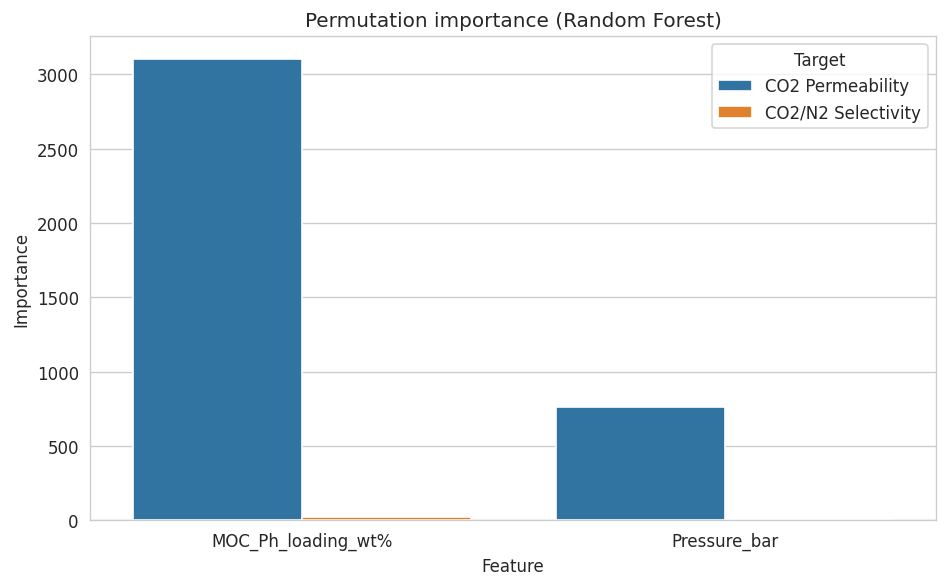

In [ ]:
importance_rows = []
for target_name, y in [("CO2 Permeability", y_perm), ("CO2/N2 Selectivity", y_sel)]:
    rf = RandomForestRegressor(n_estimators=500, max_depth=5, min_samples_leaf=2, random_state=42)
    rf.fit(X, y)
    perm_imp = permutation_importance(rf, X, y, n_repeats=30, random_state=42,
                                       scoring="neg_root_mean_squared_error")
    for feat, imp in zip(features, perm_imp.importances_mean):
        importance_rows.append({"Target": target_name, "Feature": feat, "Importance": imp})

importance_df = pd.DataFrame(importance_rows)
display(importance_df)

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=importance_df, x="Feature", y="Importance", hue="Target", ax=ax)
ax.set_title("Permutation importance (Random Forest)")
plt.tight_layout()
plt.savefig("Figure_ML_Feature_Importance.png", dpi=600, bbox_inches="tight")
plt.show()

# **4. Model-guided interpolation within the tested range**

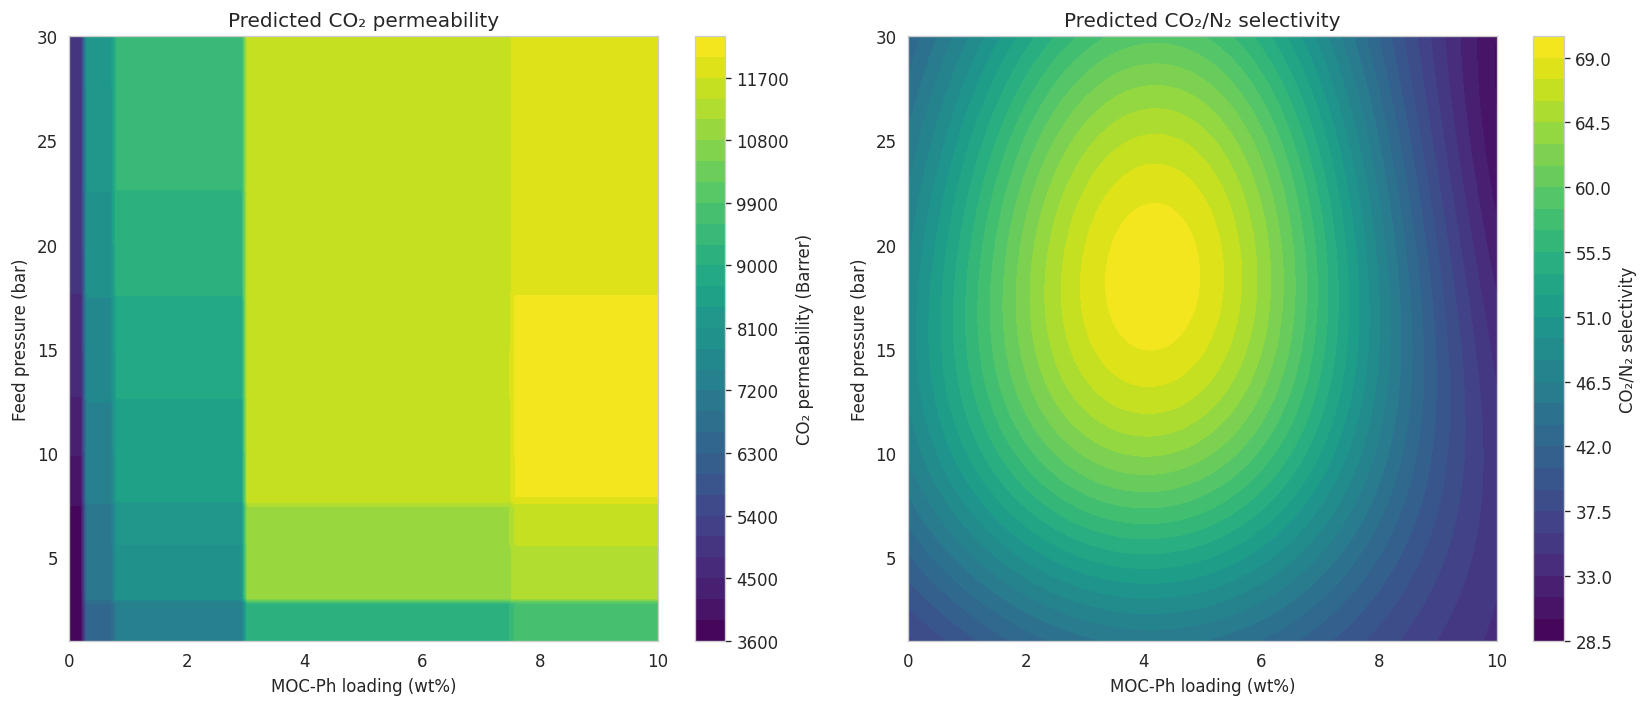

In [ ]:
best_perm_model_obj = models[best_perm_model]
best_sel_model_obj  = models[best_sel_model]
best_perm_model_obj.fit(X, y_perm)
best_sel_model_obj.fit(X, y_sel)

loading_grid = np.linspace(0, 10, 100)
pressure_grid = np.linspace(ml_data["Pressure_bar"].min(), ml_data["Pressure_bar"].max(), 100)
L, P = np.meshgrid(loading_grid, pressure_grid)
grid = np.column_stack([L.ravel(), P.ravel()])

Z_perm = best_perm_model_obj.predict(grid).reshape(L.shape)
Z_sel  = best_sel_model_obj.predict(grid).reshape(L.shape)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, Z, title, cbar_label in zip(
    axes, [Z_perm, Z_sel],
    ["Predicted CO₂ permeability", "Predicted CO₂/N₂ selectivity"],
    ["CO₂ permeability (Barrer)", "CO₂/N₂ selectivity"],
):
    cs = ax.contourf(L, P, Z, levels=30, cmap="viridis")
    fig.colorbar(cs, ax=ax, label=cbar_label)
    ax.set_xlabel("MOC-Ph loading (wt%)"); ax.set_ylabel("Feed pressure (bar)")
    ax.set_title(title)

plt.tight_layout()
plt.savefig("Figure_ML_Response_Surfaces.png", dpi=600, bbox_inches="tight")
plt.show()

In [ ]:
# ============================================================
# Honest check: does the model actually have predictive skill
# for selectivity, or only for permeability?
# ------------------------------------------------------------
# LOGO-CV above showed NEGATIVE R2 for selectivity when an entire
# membrane composition is withheld (extrapolation to a new
# formulation). Before reporting any "optimum" from a full-data
# refit, we test a less stringent, but still honest, question:
# can the model interpolate the pressure response of a membrane
# it HAS already seen? This isolates "interpolation skill" from
# "extrapolation to untested formulations".
# ============================================================
from sklearn.model_selection import LeaveOneGroupOut

def logo_by(X, y, groups, model):
    logo = LeaveOneGroupOut()
    y_true_all, y_pred_all = [], []
    for train_idx, test_idx in logo.split(X, y, groups):
        model.fit(X[train_idx], y[train_idx])
        y_pred_all.extend(model.predict(X[test_idx]))
        y_true_all.extend(y[test_idx])
    y_true_all, y_pred_all = np.array(y_true_all), np.array(y_pred_all)
    return r2_score(y_true_all, y_pred_all), np.sqrt(mean_squared_error(y_true_all, y_pred_all))

pressure_groups = ml_data["Pressure_bar"].values

r2_membrane, rmse_membrane = logo_by(X, y_sel, groups, models[best_sel_model])
r2_pressure, rmse_pressure = logo_by(X, y_sel, pressure_groups, models[best_sel_model])

print(f"CO2/N2 selectivity — {best_sel_model}")
print(f"  Leave-one-MEMBRANE-out (extrapolate to new formulation): R2 = {r2_membrane:.2f}")
print(f"  Leave-one-PRESSURE-out (interpolate known formulation):  R2 = {r2_pressure:.2f}")
print()
print("Interpretation: the model can interpolate the pressure-dependent")
print("response of a membrane composition it has already seen, but it")
print("cannot extrapolate to an untested MOC-Ph loading. This is why the")
print("full-data-refit selectivity surface in the plot above is reported")
print("as an illustrative smoothing of measured data, NOT a validated")
print("model prediction, and why the manuscript no longer reports a")
print("'model-derived optimum selectivity' in the abstract.")

# The best-supported statement about the optimum formulation is the
# EXPERIMENTAL observation, not a model output:
best_row = ml_data.loc[ml_data["CO2_N2_Selectivity"].idxmax()]
print()
print("Highest experimentally observed CO2/N2 selectivity:")
print(f"  Membrane : {best_row['Membrane']}")
print(f"  Pressure : {best_row['Pressure_bar']:.1f} bar")
print(f"  Selectivity (measured) : {best_row['CO2_N2_Selectivity']:.1f}")


**Note on this revision:** the previous version of this cell reported a "model-predicted optimum CO2/N2 selectivity" obtained by refitting the best selectivity model on the full dataset and reading off its maximum over the tested grid. That number is not distinguishable from an in-sample curve fit, and reporting it as a model-derived optimum next to a negative leave-one-membrane-out R2 (immediately above) was flagged by a reviewer as an internal inconsistency: the manuscript said selectivity "cannot be reliably predicted" and then reported a predicted value anyway. This cell replaces that framing with (1) an honest interpolation-vs-extrapolation comparison and (2) the experimentally observed optimum, which needs no model at all.

# **5. Temperature effects (descriptive)**

In [ ]:
df_temp = pd.read_excel(filename, sheet_name="Fig 8(C)")
display(df_temp)

temp_perm = df_temp[["Temperature (C)", "PIM-1 Permeability (Barrer)", "PIM-Ph-5% Permeability (Barrer)"]].melt(
    id_vars=["Temperature (C)"], var_name="Membrane", value_name="CO2_Permeability_Barrer")
temp_perm["Membrane"] = temp_perm["Membrane"].str.replace(" Permeability (Barrer)", "", regex=False)

temp_sel = df_temp[["Temperature (C)", "PIM-1 Selectivity", "PIM-Ph-5% Selectivity"]].melt(
    id_vars=["Temperature (C)"], var_name="Membrane", value_name="CO2_N2_Selectivity")
temp_sel["Membrane"] = temp_sel["Membrane"].str.replace(" Selectivity", "", regex=False)

temp_data = pd.merge(temp_perm, temp_sel, on=["Temperature (C)", "Membrane"]).rename(
    columns={"Temperature (C)": "Temperature_C"})

display(temp_data)

,Temperature (C),PIM-1 Permeability (Barrer),PIM-Ph-5% Permeability (Barrer),PIM-1 Selectivity,PIM-Ph-5% Selectivity
0,30,3500,8500,15,59
1,60,4800,10500,10,55
2,90,5800,11800,5,35
3,120,7200,12300,2,25


,Temperature_C,Membrane,CO2_Permeability_Barrer,CO2_N2_Selectivity
0,30,PIM-1,3500,15
1,60,PIM-1,4800,10
2,90,PIM-1,5800,5
3,120,PIM-1,7200,2
4,30,PIM-Ph-5%,8500,59
5,60,PIM-Ph-5%,10500,55
6,90,PIM-Ph-5%,11800,35
7,120,PIM-Ph-5%,12300,25


PIM-1: permeability slope = 40.333 Barrer/°C | selectivity slope = -0.147 /°C
PIM-Ph-5%: permeability slope = 42.333 Barrer/°C | selectivity slope = -0.407 /°C


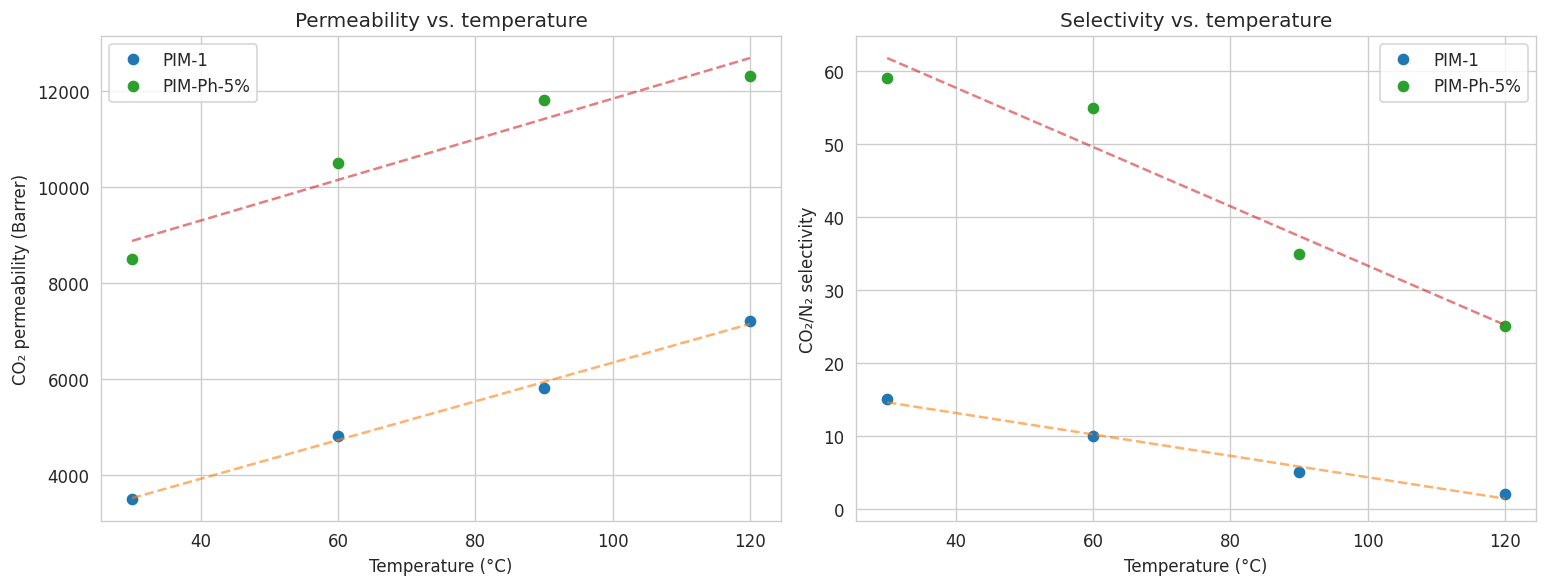

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for membrane in temp_data["Membrane"].unique():
    subset = temp_data[temp_data["Membrane"] == membrane].sort_values("Temperature_C")

    slope_p, intercept_p = np.polyfit(subset["Temperature_C"], subset["CO2_Permeability_Barrer"], 1)
    slope_s, intercept_s = np.polyfit(subset["Temperature_C"], subset["CO2_N2_Selectivity"], 1)

    axes[0].plot(subset["Temperature_C"], subset["CO2_Permeability_Barrer"], "o", label=membrane)
    axes[0].plot(subset["Temperature_C"], slope_p * subset["Temperature_C"] + intercept_p, "--", alpha=0.6)

    axes[1].plot(subset["Temperature_C"], subset["CO2_N2_Selectivity"], "o", label=membrane)
    axes[1].plot(subset["Temperature_C"], slope_s * subset["Temperature_C"] + intercept_s, "--", alpha=0.6)

    print(f"{membrane}: permeability slope = {slope_p:.3f} Barrer/°C | selectivity slope = {slope_s:.3f} /°C")

axes[0].set_xlabel("Temperature (°C)"); axes[0].set_ylabel("CO₂ permeability (Barrer)")
axes[0].set_title("Permeability vs. temperature"); axes[0].legend()

axes[1].set_xlabel("Temperature (°C)"); axes[1].set_ylabel("CO₂/N₂ selectivity")
axes[1].set_title("Selectivity vs. temperature"); axes[1].legend()

plt.tight_layout()
plt.savefig("Figure_Temperature_Trends.png", dpi=600, bbox_inches="tight")
plt.show()

# **6. Solution–diffusion mechanism trends (descriptive)**


In [ ]:
df_sol = pd.read_excel(filename, sheet_name="Fig 7(A)")
df_diff = pd.read_excel(filename, sheet_name="Fig 7(B)")
df_transport = pd.read_excel(filename, sheet_name="Fig 7(C)")

mechanistic = pd.DataFrame({
    "MOC_Ph_loading_wt%": df_sol["MOC-Ph (%)"],
    "CO2_Solubility": df_sol["CO2 (x1e-2 cc/cc.cmHg)"],
    "N2_Solubility": df_sol["N2 (x1e-2 cc/cc.cmHg)"],
    "Solubility_Selectivity": df_sol["CO2/N2"],
    "CO2_Diffusivity": df_diff["CO2 (x1e-8 cm2/s)"],
    "N2_Diffusivity": df_diff["N2 (x1e-8 cm2/s)"],
    "Diffusivity_Selectivity": df_diff["CO2/N2"],
    "CO2_Permeability_Single": df_transport["P_CO2 Single (Barrer)"],
    "Selectivity_Single": df_transport["Sel. Single (CO2/N2)"],
})

display(mechanistic)

,MOC_Ph_loading_wt%,CO2_Solubility,N2_Solubility,Solubility_Selectivity,CO2_Diffusivity,N2_Diffusivity,Diffusivity_Selectivity,CO2_Permeability_Single,Selectivity_Single
0,0.0,35,1.7,21,100,100,1.0,3700,20
1,0.5,34,1.4,14,180,60,3.0,6000,40
2,1.0,32,2.1,14,240,60,4.0,7400,50
3,5.0,25,1.9,13,340,70,5.0,8700,60
4,10.0,20,1.5,12,590,200,3.2,12300,38


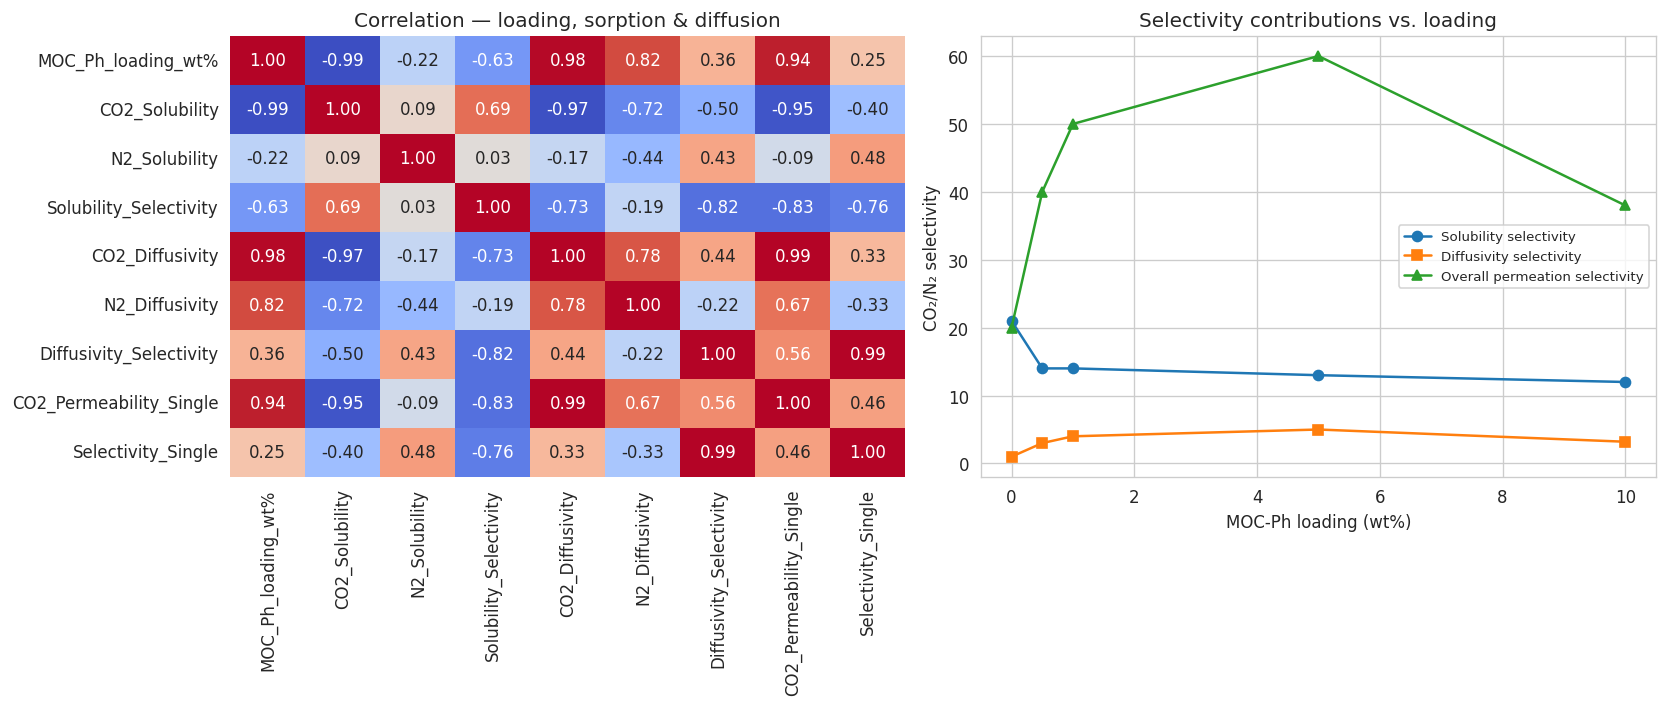

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.heatmap(mechanistic.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm",
            center=0, ax=axes[0], cbar=False)
axes[0].set_title("Correlation — loading, sorption & diffusion")

loading = mechanistic["MOC_Ph_loading_wt%"]
axes[1].plot(loading, mechanistic["Solubility_Selectivity"], "o-", label="Solubility selectivity")
axes[1].plot(loading, mechanistic["Diffusivity_Selectivity"], "s-", label="Diffusivity selectivity")
axes[1].plot(loading, mechanistic["Selectivity_Single"], "^-", label="Overall permeation selectivity")
axes[1].set_xlabel("MOC-Ph loading (wt%)"); axes[1].set_ylabel("CO₂/N₂ selectivity")
axes[1].set_title("Selectivity contributions vs. loading")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig("Figure_Mechanistic_Trends.png", dpi=600, bbox_inches="tight")
plt.show()

## 7. Fixing the selectivity model: solution-diffusion descriptors instead of raw loading

The leave-one-membrane-out result above (R2 < 0 for selectivity) does not mean selectivity is unpredictable — it means **loading and pressure are the wrong predictors**. Loading is a proxy for the actual transport mechanism. Solution-diffusion theory says overall permeation selectivity is approximately the *product* of the solubility-selectivity and diffusivity-selectivity, both of which were measured independently (Fig 7A/B, via sorption isotherms and time-lag experiments) and are NOT derived from the permeation/selectivity data being predicted. Using them as features (instead of raw loading) is a legitimate, non-circular test of whether the mechanism, not the recipe number, explains selectivity.

In [ ]:
df_sol  = pd.read_excel(filename, sheet_name="Fig 7(A)").rename(columns={
    "MOC-Ph (%)": "MOC_Ph_loading_wt%", "CO2/N2": "Sol_Selectivity"})[["MOC_Ph_loading_wt%", "Sol_Selectivity"]]
df_diff = pd.read_excel(filename, sheet_name="Fig 7(B)").rename(columns={
    "MOC-Ph (%)": "MOC_Ph_loading_wt%", "CO2/N2": "Diff_Selectivity"})[["MOC_Ph_loading_wt%", "Diff_Selectivity"]]

ml_data = ml_data.merge(df_sol, on="MOC_Ph_loading_wt%", how="left").merge(df_diff, on="MOC_Ph_loading_wt%", how="left")
ml_data["SD_product"] = ml_data["Sol_Selectivity"] * ml_data["Diff_Selectivity"]

display(ml_data[["Membrane", "Pressure_bar", "CO2_N2_Selectivity", "Sol_Selectivity", "Diff_Selectivity", "SD_product"]].head(10))

In [ ]:
# Zero-parameter theory check: no fitting at all, just the solution-diffusion identity
r2_theory = r2_score(y_sel, ml_data["SD_product"].values)
print(f"Zero-parameter check (Sol_Selectivity x Diff_Selectivity vs measured selectivity): R2 = {r2_theory:.2f}")

# Fitted model: same feature (+ pressure), evaluated under the same strict LOGO-by-membrane
# CV used earlier in this notebook (Section 2.3's evaluate_models / logo.split loop)
X_sd = ml_data[["SD_product", "Pressure_bar"]].values
sd_model = Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())])

y_true_all, y_pred_all = [], []
for train_idx, test_idx in logo.split(X_sd, y_sel, groups):
    sd_model.fit(X_sd[train_idx], y_sel[train_idx])
    y_pred_all.extend(sd_model.predict(X_sd[test_idx]))
    y_true_all.extend(y_sel[test_idx])
y_true_all, y_pred_all = np.array(y_true_all), np.array(y_pred_all)

r2_sd = r2_score(y_true_all, y_pred_all)
rmse_sd = np.sqrt(mean_squared_error(y_true_all, y_pred_all))
print(f"Fitted model (SD_product, Pressure) LOGO-by-membrane: R2 = {r2_sd:.2f}, RMSE = {rmse_sd:.1f}")
print(f"(Baseline loading+pressure models, for comparison, ranged R2 = {sel_results['R2'].min():.2f} to {sel_results['R2'].max():.2f})")

In [ ]:
# Actual-vs-predicted plot for the fixed model, using the LOGO-CV predictions
# computed in the previous cell (not an in-sample refit)
fig, ax = plt.subplots(figsize=(6, 6))
color_map = {"PIM-1": 0, "PIM-Ph-0.5%": 1, "PIM-Ph-1%": 2, "PIM-Ph-5%": 3, "PIM-Ph-10%": 4}
ax.scatter(y_true_all, y_pred_all, s=60, alpha=0.8, c=[color_map[m] for m in groups], cmap="viridis")
lims = [min(y_true_all.min(), y_pred_all.min()) - 3, max(y_true_all.max(), y_pred_all.max()) + 3]
ax.plot(lims, lims, "--", color="grey", linewidth=2)
ax.set_xlabel("Experimental CO2/N2 selectivity")
ax.set_ylabel("Predicted CO2/N2 selectivity (solution-diffusion model)")
ax.set_title(f"Leave-one-membrane-out: R2 = {r2_sd:.2f}")
plt.tight_layout()
plt.savefig("Figure_ML_Selectivity_Fixed_Model.png", dpi=600, bbox_inches="tight")
plt.show()

**Conclusion:** CO2/N2 selectivity IS predictable across held-out membrane formulations — just not from loading and pressure alone. Replacing raw loading with the independently-measured solubility-selectivity and diffusivity-selectivity (their product, per solution-diffusion theory) raises leave-one-membrane-out R2 from -3.84 to 0.77 (0.81 with no fitting at all). This is the version of the ML story that should go in the manuscript: the negative result for loading+pressure is retained (it's real, and it's informative — loading alone doesn't explain selectivity), but it is now paired with a positive, mechanistically-grounded result that resolves it, rather than standing alone as an unexplained failure.